# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import seaborn as sns

In [2]:
df = pd.read_csv('teams.csv')
df.head()

,team,country,year,events,athletes,age,height,weight,medals,prev_medals,prev_3_medals
0,AFG,Afghanistan,1964,8,8,22.0,161.0,64.2,0,0.0,0.0
1,AFG,Afghanistan,1968,5,5,23.2,170.2,70.0,0,0.0,0.0
2,AFG,Afghanistan,1972,8,8,29.0,168.3,63.8,0,0.0,0.0
3,AFG,Afghanistan,1980,11,11,23.6,168.4,63.2,0,0.0,0.0
4,AFG,Afghanistan,2004,5,5,18.6,170.8,64.8,0,0.0,0.0


In [3]:
df = pd.read_csv('fake reviews dataset.csv')
df.head()

,category,rating,label,text_
0,Home_and_Kitchen_5,5.0,CG,"Love this! Well made, sturdy, and very comfor..."
1,Home_and_Kitchen_5,5.0,CG,"love it, a great upgrade from the original. I..."
2,Home_and_Kitchen_5,5.0,CG,This pillow saved my back. I love the look and...
3,Home_and_Kitchen_5,1.0,CG,"Missing information on how to use it, but it i..."
4,Home_and_Kitchen_5,5.0,CG,Very nice set. Good quality. We have had the s...


# Data preparation

In [4]:
df.shape

(40432, 4)

In [5]:
df.columns

Index(['category', 'rating', 'label', 'text_'], dtype='object')

In [6]:
df["category"].value_counts()

category
Kindle_Store_5                  4730
Books_5                         4370
Pet_Supplies_5                  4254
Home_and_Kitchen_5              4056
Electronics_5                   3988
Sports_and_Outdoors_5           3946
Tools_and_Home_Improvement_5    3858
Clothing_Shoes_and_Jewelry_5    3848
Toys_and_Games_5                3794
Movies_and_TV_5                 3588
Name: count, dtype: int64

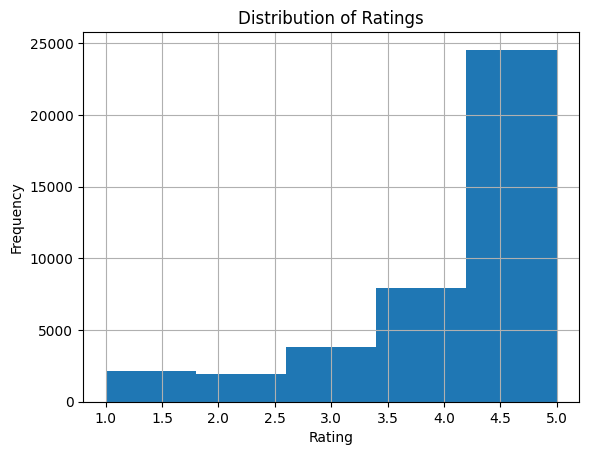

In [7]:
df['rating'].hist(bins=5)
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.title('Distribution of Ratings')
plt.show()

Text(0.5, 1.0, 'Count of Real vs Fake Reviews')

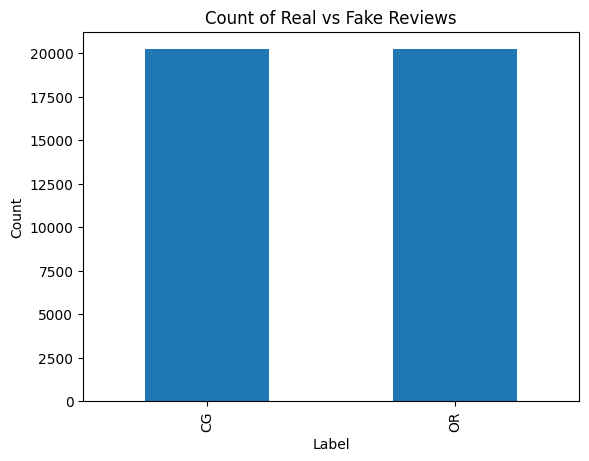

In [8]:
df['label'].value_counts().plot(kind='bar')
plt.xlabel('Label')
plt.ylabel('Count')
plt.title('Count of Real vs Fake Reviews')

# CG = Computer Generated  - OR = Original Review

In [9]:
df['label'].value_counts()

label
CG    20216
OR    20216
Name: count, dtype: int64

In [10]:
df.isnull().sum()

category    0
rating      0
label       0
text_       0
dtype: int64

In [11]:
df["label_num"] = df["label"].map({"OR": 1, "CG": 0})
df['label_num'].value_counts()

label_num
0    20216
1    20216
Name: count, dtype: int64

In [12]:
df[["label", "label_num"]].head()

,label,label_num
0,CG,0
1,CG,0
2,CG,0
3,CG,0
4,CG,0


In [13]:
df_bin = df.copy()

In [14]:
df_bin["text_"].iloc[0]

'Love this!  Well made, sturdy, and very comfortable.  I love it!Very pretty'

In [15]:
from nltk.corpus import stopwords
import re
import string

stop_words = set(stopwords.words("english"))

def clean_text(text):
    # lowercase
    text = text.lower()
    
    # remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))
    
    # remove numbers
    text = re.sub(r"\d+", "", text)
    
    # remove stopwords
    text = " ".join(word for word in text.split() if word not in stop_words)
    
    # remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text


In [16]:
sample_text = df_bin["text_"].iloc[0]
clean_text(sample_text)

'love well made sturdy comfortable love itvery pretty'

In [17]:
df_bin["clean_text"] = df_bin["text_"].apply(clean_text)

In [18]:
df_bin[["text_", "clean_text"]].head()

,text_,clean_text
0,"Love this! Well made, sturdy, and very comfor...",love well made sturdy comfortable love itvery ...
1,"love it, a great upgrade from the original. I...",love great upgrade original ive mine couple years
2,This pillow saved my back. I love the look and...,pillow saved back love look feel pillow
3,"Missing information on how to use it, but it i...",missing information use great product price
4,Very nice set. Good quality. We have had the s...,nice set good quality set two months


In [19]:
import nltk
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\DELL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [21]:
tfidf = TfidfVectorizer(
    max_features=5000,   # keep top 5000 words
    ngram_range=(1, 2)   # unigrams + bigrams (modern & useful)
)

In [22]:
X = tfidf.fit_transform(df_bin["clean_text"])
y = df_bin["label_num"]

In [23]:
X.shape, y.shape

((40432, 5000), (40432,))

In [24]:
tfidf.get_feature_names_out()[:20]

array(['aa', 'ability', 'able', 'able find', 'able get', 'able put',
       'able use', 'abrupt', 'absolute', 'absolutely', 'absolutely love',
       'absolutely loved', 'absolutely loves', 'absorbent', 'abuse', 'ac',
       'accept', 'access', 'accessories', 'accident'], dtype=object)

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((32345, 5000), (8087, 5000), (32345,), (8087,))

# Modeling

In [26]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score, f1_score

In [27]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC()
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append([name, acc, f1])
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1 Score"])
results_df.sort_values(by="F1 Score", ascending=False)

,Model,Accuracy,F1 Score
2,Linear SVM,0.894027,0.893421
1,Logistic Regression,0.888710,0.889217
0,Naive Bayes,0.859280,0.862161


In [28]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    "C": [0.01, 0.1, 1, 10]
}
svm = LinearSVC()

grid = GridSearchCV(
    svm,
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)
grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=LinearSVC(), n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10]}, scoring='f1')

In [29]:
grid.best_params_

{'C': 1}

In [30]:
best_svm = grid.best_estimator_

y_pred_best = best_svm.predict(X_test)
acc_best = accuracy_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)
acc_best, f1_best

(0.8940274514653147, 0.8934212162666335)

Linear SVM	     | 0.894027 | 0.893421 \
Linear SVM best  | 0.894027 | 0.893421

The same perfomance

In [31]:
# ===== SAVE, LOAD, AND PREDICT IN ONE CELL =====

import joblib

# ---- SAVE ----
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
joblib.dump(best_svm, "linear_svm_model.pkl")

print("✅ Model and vectorizer saved")

# ---- LOAD ----
tfidf_loaded = joblib.load("tfidf_vectorizer.pkl")
model_loaded = joblib.load("linear_svm_model.pkl")

print("✅ Model and vectorizer loaded")

✅ Model and vectorizer saved
✅ Model and vectorizer loaded


In [32]:
# ---- PREDICT ON NEW TEXT ----
new_review = "This product is amazing, high quality and worth the price"

cleaned_review = [clean_text(new_review)]
X_new = tfidf_loaded.transform(cleaned_review)

prediction = model_loaded.predict(X_new)

if prediction[0] == 1:
    print("🟢 Prediction: Real Review")
else:
    print("🔴 Prediction: Fake Review")

🟢 Prediction: Real Review


# The obvious fake are not detected!

In [33]:
def behavioral_features(text):
    words = text.split()
    
    return {
        "length": len(text),                                # total characters
        "word_count": len(words),                           # number of words
        "exclamation_count": text.count("!"),               # !!! signal
        "capital_ratio": sum(1 for c in text if c.isupper()) / max(len(text), 1),
        "repetition_ratio": len(words) / max(len(set(words)), 1)
    }

# Apply to original (UNCLEANED) text
behavior_df = df_bin["text_"].apply(behavioral_features).apply(pd.Series)

behavior_df.head()

,length,word_count,exclamation_count,capital_ratio,repetition_ratio
0,75.0,12.0,2.0,0.053333,1.000000
1,80.0,16.0,0.0,0.012500,1.066667
2,67.0,14.0,0.0,0.029851,1.000000
3,81.0,17.0,1.0,0.024691,1.000000
4,85.0,18.0,0.0,0.035294,1.058824


In [34]:
from scipy.sparse import hstack

X_combined = hstack([X, behavior_df.values])

In [35]:
X_train_c, X_test_c, y_train, y_test = train_test_split(
    X_combined,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm_adv = LinearSVC(C=grid.best_params_["C"])
svm_adv.fit(X_train_c, y_train)

y_pred_adv = svm_adv.predict(X_test_c)

accuracy_score(y_test, y_pred_adv), f1_score(y_test, y_pred_adv)


(0.913812291331767, 0.9140884999383705)

In [37]:
test_text = "BEST PRODUCT EVER!!! AMAZING AMAZING BUY NOW!!!"

cleaned = clean_text(test_text)
X_text = tfidf.transform([cleaned])
X_behav = np.array([list(behavioral_features(test_text).values())])

X_final = hstack([X_text, X_behav])

svm_adv.predict(X_final)


array([0])

In [38]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC()
}

results = []

for name, model in models.items():
    model.fit(X_train_c, y_train)
    y_pred = model.predict(X_test_c)
    
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append([name, acc, f1])
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "F1 Score"])
results_df.sort_values(by="F1 Score", ascending=False)

c:\Users\DELL\Desktop\test\venvtest\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,F1 Score
2,Linear SVM,0.913812,0.914088
1,Logistic Regression,0.904167,0.905059
0,Naive Bayes,0.849635,0.843983


In [39]:
import joblib

# Save TF-IDF vectorizer (same as before)
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

# Save the ADVANCED trained model (TF-IDF + behavior features)
joblib.dump(svm_adv, "linear_svm_model_adv.pkl")

print("✅ Updated model and vectorizer saved successfully")

✅ Updated model and vectorizer saved successfully


In [40]:
def extract_behavior_features(text):
    words = text.split()

    return np.array([
        len(text),                                  # 1. character length
        len(words),                                 # 2. word count
        text.count("!"),                            # 3. exclamation count
        sum(1 for c in text if c.isupper()) / max(len(text), 1),  # 4. capital ratio
        len(words) / max(len(set(words)), 1)        # 5. repetition ratio
    ]).reshape(1, -1)


In [41]:
# Recreate behavior features for ALL data
behavior_features = np.array(
    df_bin["text_"].apply(lambda x: extract_behavior_features(x).flatten()).tolist()
)

from scipy.sparse import hstack
X_combined = hstack([X, behavior_features])

from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

X_train_c, X_test_c, y_train, y_test = train_test_split(
    X_combined,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm_adv = LinearSVC(C=1)
svm_adv.fit(X_train_c, y_train)


LinearSVC(C=1)

In [42]:
import joblib

joblib.dump(tfidf, "tfidf_vectorizer.pkl")
joblib.dump(svm_adv, "linear_svm_model_adv.pkl")

print("✅ Model retrained and saved with 5005 features")

✅ Model retrained and saved with 5005 features
